In [1]:
import numpy as np
import networkx as nx
from sklearn.cluster import KMeans
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

In [2]:
# =========================================
# 基础：从 W 拆成 A+ / A-
# =========================================
def build_signed_digraph_from_W(W, threshold=None, keep_diag=False):
    """
    返回 (G_plus, G_minus) 两个 DiGraph；边权非负。
    A_plus[u,v] = max(W[u,v],0)；A_minus[u,v] = max(-W[u,v],0)
    """
    W_pos = np.maximum(W, 0.0).copy()
    W_neg = np.maximum(-W, 0.0).copy()

    if not keep_diag:
        np.fill_diagonal(W_pos, 0.0)
        np.fill_diagonal(W_neg, 0.0)

    if threshold is not None:
        W_pos = np.where(W_pos >= threshold, W_pos, 0.0)
        W_neg = np.where(W_neg >= threshold, W_neg, 0.0)

    Gp = nx.from_numpy_array(W_pos, create_using=nx.DiGraph)
    Gn = nx.from_numpy_array(W_neg, create_using=nx.DiGraph)
    for u, v, d in Gp.edges(data=True):
        d['weight'] = float(W_pos[u, v])
    for u, v, d in Gn.edges(data=True):
        d['weight'] = float(W_neg[u, v])
    return Gp, Gn

def digraph_to_adj(G):
    n = G.number_of_nodes()
    A = np.zeros((n, n), dtype=float)
    for u, v, d in G.edges(data=True):
        A[u, v] += d.get('weight', 1.0)
    return A

# =========================================
# A. 2n 提升（lifting）
# -----------------------------------------
# 对有向符号图，构造 2n×2n 的非负有向邻接：
#   B = [[A+, A-],
#        [A-, A+]]
# 直观：正边连接“同符号副本”，负边连接“异符号副本”
# 然后对 B 跑 MCL / 谱分割，最后把 2n 个标签还原到 n 个节点
# =========================================
def lift_signed_digraph(A_pos, A_neg):
    A_pos = np.asarray(A_pos); A_neg = np.asarray(A_neg)
    n = A_pos.shape[0]
    top = np.concatenate([A_pos, A_neg], axis=1)
    bot = np.concatenate([A_neg, A_pos], axis=1)
    B = np.concatenate([top, bot], axis=0)
    return B  # (2n, 2n)

def row_stochastic(M):
    rs = M.sum(axis=1, keepdims=True) + 1e-12
    return M / rs

def mcl_matrix(M, expand_power=2, inflate_r=1.6, self_loop=1.0, max_iter=200, tol=1e-9, verbose=False):
    # 在行随机游走空间做 MCL
    M = M.copy().astype(float)
    M = M + np.eye(M.shape[0]) * self_loop
    M = row_stochastic(M)
    last = None
    for it in range(max_iter):
        M = np.linalg.matrix_power(M, expand_power)
        M = np.power(M, inflate_r)
        M = row_stochastic(M)
        if last is not None:
            diff = np.abs(M - last).sum()
            if verbose:
                print(f"[MCL-lift] iter={it} diff={diff:.3e}")
            if diff < tol:
                break
        last = M.copy()
    return M

def mcl_classic(M, expand_power=2, inflate_r=2.2, self_loop=0.1,
                prune=1e-3, max_iter=200, tol=1e-7, verbose=False):
    """
    Classic MCL in column-stochastic space.
    Parameters mirror mcl_matrix; adds `prune`.
      - expand_power: 2 or 3 are common
      - inflate_r:    1.8~2.5 typical (2.0~2.2 often good)
      - self_loop:    small positive; scaled by matrix mean
      - prune:        zero out small entries after inflation
    Returns:
      Column-stochastic matrix after convergence.
    """
    M = np.asarray(M, dtype=float).copy()
    n = M.shape[0]

    # add self-loop scaled by mean (avoid overly lazy walk)
    mu = M.mean() if M.size else 0.0
    M = M + np.eye(n) * (self_loop * (mu if mu > 0 else 1.0))

    def col_stochastic(X):
        cs = X.sum(axis=0, keepdims=True) + 1e-12
        return X / cs

    # initialize as column-stochastic
    M = col_stochastic(M)

    last = None
    for it in range(max_iter):
        # expansion
        if expand_power == 2:
            M = M @ M
        else:
            M = np.linalg.matrix_power(M, expand_power)

        # inflation
        M = np.power(M, inflate_r)

        # pruning (sparsify) + renormalize
        if prune is not None and prune > 0.0:
            M[M < prune] = 0.0
        M = col_stochastic(M)

        if last is not None:
            diff = np.abs(M - last).sum()
            if verbose:
                print(f"[MCL-classic] iter={it} diff={diff:.3e}")
            if diff < tol:
                break
        last = M.copy()

    return M

def labels_from_mcl_matrix(M):
    raw = M.argmax(axis=1)
    uniq = {v:i for i, v in enumerate(np.unique(raw))}
    return np.array([uniq[v] for v in raw], dtype=int)

def signed_partition_lifting_MCL(W, threshold=None, keep_diag=True,
                                 expand_power=2, inflate_r=1.6, self_loop=1.0):
    Gp, Gn = build_signed_digraph_from_W(W, threshold=threshold, keep_diag=keep_diag)
    Apos, Aneg = digraph_to_adj(Gp), digraph_to_adj(Gn)
    B = lift_signed_digraph(Apos, Aneg)  # (2n, 2n)
    M = mcl_classic(B, expand_power=expand_power, inflate_r=inflate_r, self_loop=self_loop)
    labels_2n = labels_from_mcl_matrix(M)
    # 折回 n 个节点：取两个副本的多数（若不一致则取第一个）
    n = Apos.shape[0]
    lab_top, lab_bot = labels_2n[:n], labels_2n[n:]
    labels = np.where(lab_top == lab_bot, lab_top, lab_top)  # 简单聚合；也可加一致性修复
    return (Gp, Gn), labels

def signed_partition_lifting_spectral(W, k, threshold=None, keep_diag=True, random_state=0):
    Gp, Gn = build_signed_digraph_from_W(W, threshold=threshold, keep_diag=keep_diag)
    Apos, Aneg = digraph_to_adj(Gp), digraph_to_adj(Gn)
    B = lift_signed_digraph(Apos, Aneg)  # (2n, 2n)
    # 取 B 的前 k 个奇异向量（或特征向量），再 k-means
    try:
        U, S, Vt = svds(csr_matrix(B), k=min(k, B.shape[0]-1))
        X = U
    except Exception:
        U, S, Vt = np.linalg.svd(B, full_matrices=False)
        X = U[:, :k]
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    km = KMeans(n_clusters=k, n_init=10, random_state=random_state).fit(X)
    labels_2n = km.labels_
    n = Apos.shape[0]
    lab_top, lab_bot = labels_2n[:n], labels_2n[n:]
    labels = np.where(lab_top == lab_bot, lab_top, lab_top)
    return (Gp, Gn), labels

# =========================================
# B. 有向“签名谱嵌入”（不提升）
# -----------------------------------------
# 用 M^+ = D_out+^{-1/2} A^+ D_in+^{-1/2} 的左奇异向量，
# 与 M^- 的左奇异向量拼接，负边部分取相反号，以体现“排斥”
# 再做 k-means
# =========================================
def directed_signed_spectral_from_W(W, k, threshold=None, keep_diag=False, random_state=0):
    Gp, Gn = build_signed_digraph_from_W(W, threshold=threshold, keep_diag=keep_diag)
    Apos, Aneg = digraph_to_adj(Gp), digraph_to_adj(Gn)
    kout_p, kin_p = Apos.sum(axis=1), Apos.sum(axis=0)
    kout_n, kin_n = Aneg.sum(axis=1), Aneg.sum(axis=0)

    def norm_embed(A, kout, kin, k_use):
        kout = np.maximum(kout, 1e-12)
        kin  = np.maximum(kin,  1e-12)
        Dout_is = np.diag(1.0/np.sqrt(kout))
        Din_is  = np.diag(1.0/np.sqrt(kin))
        M = Dout_is @ A @ Din_is
        try:
            U, S, Vt = svds(csr_matrix(M), k=min(k_use, M.shape[0]-1))
            X = U
        except Exception:
            U, S, Vt = np.linalg.svd(M, full_matrices=False)
            X = U[:, :k_use]
        return X

    k_half = max(1, k//2)
    Xp = norm_embed(Apos, kout_p, kin_p, k_half)   # 吸引
    Xn = norm_embed(Aneg, kout_n, kin_n, k - k_half)  # 排斥
    # 负边用相反号（把“相似度”翻成“差异度”）
    X = np.concatenate([Xp, -Xn], axis=1)
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    km = KMeans(n_clusters=k, n_init=10, random_state=random_state).fit(X)
    labels = km.labels_
    return (Gp, Gn), labels

# =========================================
# 评分指标
# =========================================
def signed_directed_modularity(W, labels):
    """
    有向符号模块度（Traag & Bruggeman 风格的有向扩展）：
    Q =  (1/m+) * sum_{ij in same} [A+_ij - kout+_i * kin+_j / m+]
       - (1/m-) * sum_{ij in same} [A-_ij - kout-_i * kin-_j / m-]
    正边鼓励同簇，负边惩罚同簇（鼓励跨簇）。
    """
    Gp, Gn = build_signed_digraph_from_W(W, keep_diag=False)
    Apos, Aneg = digraph_to_adj(Gp), digraph_to_adj(Gn)
    kout_p, kin_p = Apos.sum(axis=1), Apos.sum(axis=0)
    kout_n, kin_n = Aneg.sum(axis=1), Aneg.sum(axis=0)
    mp = Apos.sum(); mn = Aneg.sum()
    labels = np.asarray(labels)

    def part_Q(A, kout, kin, m, sign=+1.0):
        if m <= 0: return 0.0
        Q = 0.0
        for i in range(A.shape[0]):
            li = labels[i]
            for j in range(A.shape[1]):
                if labels[j] == li:
                    Pij = (kout[i] * kin[j]) / (m + 1e-12)
                    Q += (A[i, j] - Pij)
        return sign * (Q / (m + 1e-12))

    return float(part_Q(Apos, kout_p, kin_p, mp, +1.0) + part_Q(Aneg, kout_n, kin_n, mn, -1.0))

def signed_frustration(W, labels):
    """
    挫折率（越小越好）：
      Frust = ( 正边跨簇 + 负边同簇 ) / ( |A+| + |A-| )
    """
    Gp, Gn = build_signed_digraph_from_W(W, keep_diag=False)
    Apos, Aneg = digraph_to_adj(Gp), digraph_to_adj(Gn)
    labels = np.asarray(labels)
    mp, mn = Apos.sum(), Aneg.sum()
    if mp + mn <= 0: return 0.0

    # 正边跨簇
    cross_pos = 0.0
    same_neg  = 0.0
    n = Apos.shape[0]
    for i in range(n):
        for j in range(n):
            if labels[i] != labels[j]:
                cross_pos += Apos[i, j]
            else:
                same_neg  += Aneg[i, j]
    return float((cross_pos + same_neg) / (mp + mn + 1e-12))

def signed_weighted_ncut(W, labels):
    """
    有向符号 Ncut（越小越好）：
    对每个簇 C：
      Ncut_C = [ (A+_{C,~C} + A-_{C,C}) / vol_out^+(C∪-)  +  (A+_{~C,C} + A-_{C,C}) / vol_in^+(C∪-) ] / 2
    直觉：把“好”的流量视作 正边留在簇内 + 负边跨簇；“坏”的流量反过来。
    实现上给一个合理但简洁的近似。
    """
    Gp, Gn = build_signed_digraph_from_W(W, keep_diag=False)
    Apos, Aneg = digraph_to_adj(Gp), digraph_to_adj(Gn)
    kout_p, kin_p = Apos.sum(axis=1), Apos.sum(axis=0)
    kout_n, kin_n = Aneg.sum(axis=1), Aneg.sum(axis=0)
    labels = np.asarray(labels)
    K = np.unique(labels)
    ncut = 0.0
    for c in K:
        C = np.where(labels == c)[0]
        notC = np.where(labels != c)[0]
        # “坏”流：正边出簇、正边入簇、负边留在簇内
        bad_out = Apos[np.ix_(C, notC)].sum() + Aneg[np.ix_(C, C)].sum()
        bad_in  = Apos[np.ix_(notC, C)].sum() + Aneg[np.ix_(C, C)].sum()
        vol_out = (kout_p[C].sum() + kout_n[C].sum()) + 1e-12
        vol_in  = (kin_p[C].sum()  + kin_n[C].sum()) + 1e-12
        ncut += 0.5 * (bad_out / vol_out + bad_in / vol_in)
    return float(ncut / len(K))


In [3]:
np.random.seed(1)
H = 60
W = 0.08*np.random.randn(H, H)
# 做 3 个“功能簇”：簇内正权+，簇间负权-
blocks = np.array_split(np.arange(H), 3)
for b, idx in enumerate(blocks):
    W[np.ix_(idx, idx)] += 0.25  # 簇内变成更多正边
for a in range(3):
    for b in range(3):
        if a != b:
            ia, ib = blocks[a], blocks[b]
            W[np.ix_(ia, ib)] -= 0.20  # 簇间更多负边

# A) 提升 + MCL
(Gp, Gn), lab_mcl = signed_partition_lifting_MCL(W, keep_diag=True, inflate_r=1.6)
Qm = signed_directed_modularity(W, lab_mcl)
Fm = signed_frustration(W, lab_mcl)
Nm = signed_weighted_ncut(W, lab_mcl)
print(f"[Signed-Lift MCL] k={len(np.unique(lab_mcl))}  Q={Qm:.4f}  Frustr={Fm:.4f}  Ncut={Nm:.4f}")

# B) 提升 + 谱分割（设定 k）
(Gp, Gn), lab_sp = signed_partition_lifting_spectral(W, k=3, keep_diag=True)
Qs = signed_directed_modularity(W, lab_sp)
Fs = signed_frustration(W, lab_sp)
Ns = signed_weighted_ncut(W, lab_sp)
print(f"[Signed-Lift Spectral] k={len(np.unique(lab_sp))}  Q={Qs:.4f}  Frustr={Fs:.4f}  Ncut={Ns:.4f}")

# C) 有向签名谱嵌入（不提升）
(Gp, Gn), lab_ds = directed_signed_spectral_from_W(W, k=3, keep_diag=False)
Qd = signed_directed_modularity(W, lab_ds)
Fd = signed_frustration(W, lab_ds)
Nd = signed_weighted_ncut(W, lab_ds)
print(f"[Direct Signed Spectral] k={len(np.unique(lab_ds))}  Q={Qd:.4f}  Frustr={Fd:.4f}  Ncut={Nd:.4f}")


[Signed-Lift MCL] k=3  Q=-0.0008  Frustr=0.6091  Ncut=0.4531
[Signed-Lift Spectral] k=3  Q=0.9984  Frustr=0.0006  Ncut=0.0006
[Direct Signed Spectral] k=3  Q=0.9984  Frustr=0.0006  Ncut=0.0006


In [4]:
def ei_violation_fraction(W, axis=1):
    # axis=1: 按行检查；axis=0: 按列检查
    pos_any = (W > 0).any(axis=axis)
    neg_any = (W < 0).any(axis=axis)
    mixed = pos_any & neg_any   # 同一行/列同时有正有负 -> 违反 EI
    return mixed.mean()

def orient_W_row_out(W):
    # 选择“行作为 outgoing”更贴近 EI 的方向
    row_violate = ei_violation_fraction(W, axis=1)
    col_violate = ei_violation_fraction(W, axis=0)
    print(f"Row-violate: {row_violate:.4f}  Col-violate: {col_violate:.4f}")
    if col_violate < row_violate:
        return W.T, True   # 转置后“行”更同号 → 用转置
    else:
        return W, False    # 不转置

In [5]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F
from IPython.display import clear_output
from pdm_model import Net, SimpleNet
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation
kwargs = {'dt': dt, 'dim_ring': dim_ring}
seq_len = 100
tasks = get_collection('yang19')
envs = [ngym.make(task, **kwargs) for task in tasks]
schedule = RandomSchedule(len(envs))
env = ScheduleEnvs(envs, schedule=schedule, env_input=True)
seq_len = 100
batch_size = 32
dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)
env = dataset.env
ob_size = env.observation_space.shape[0]
act_size = env.action_space.n
device = 'cuda'
hidden_size = 64
net = Net(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)
# net.load_state_dict(torch.load('./model/multitask/yang19_ei_softplus.pth', map_location=device))
# simple_net.load_state_dict(torch.load('./model/multitask/yang19_simple_softplus.pth', map_location=device))


/cephfs/wangjiyi/miniconda3/envs/neurogym/lib/python3.11/site-packages/gymnasium/core.py:311: UserWarning: WARN: env.new_trial to get variables from other wrappers is deprecated and will be removed in v1.0, to get this variable you can do `env.unwrapped.new_trial` for environment variables or `env.get_wrapper_attr('new_trial')` that will search the reminding wrappers.
  logger.warn(
/cephfs/wangjiyi/miniconda3/envs/neurogym/lib/python3.11/site-packages/gymnasium/core.py:311: UserWarning: WARN: env.seed to get variables from other wrappers is deprecated and will be removed in v1.0, to get this variable you can do `env.unwrapped.seed` for environment variables or `env.get_wrapper_attr('seed')` that will search the reminding wrappers.
  logger.warn(
/cephfs/wangjiyi/miniconda3/envs/neurogym/lib/python3.11/site-packages/gymnasium/core.py:311: UserWarning: WARN: env.ob to get variables from other wrappers is deprecated and will be removed in v1.0, to get this variable you can do `env.unwrap

In [6]:
device='cuda:0'
batch_size = 64
hidden_size = 64
input_size = 1  # [number, indicator]
output_size = 25  # regression output
simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
net_path = './model/sort/ei_net.pth'
simple_net_path = './model/sort/simple_net.pth'
net.load_state_dict(torch.load(net_path))
simple_net.load_state_dict(torch.load(simple_net_path))

<All keys matched successfully>

In [7]:
import pandas as pd

# —— 小工具：把标签压缩为 0..K-1，并返回有效簇数 ——
def _compress_labels(labels):
    labels = np.asarray(labels)
    uniq = {v:i for i, v in enumerate(np.unique(labels))}
    lab  = np.array([uniq[v] for v in labels], dtype=int)
    return lab, len(uniq)

# —— 单次评估：给定 W 与 k，跑一种方法求分数 ——
def _eval_one_k(W, k, method, keep_diag=True, random_state=0):
    if method == "lift":
        (Gp, Gn), lab = signed_partition_lifting_spectral(W, k=k, keep_diag=keep_diag, random_state=random_state)
    elif method == "direct":
        (Gp, Gn), lab = directed_signed_spectral_from_W(W, k=k, keep_diag=keep_diag, random_state=random_state)
    else:
        raise ValueError("method must be 'lift' or 'direct'")
    lab, k_eff = _compress_labels(lab)
    Q  = signed_directed_modularity(W, lab)
    Fr = signed_frustration(W, lab)
    Nc = signed_weighted_ncut(W, lab)
    return {"k": k, "k_eff": k_eff, "Q": Q, "Frustr": Fr, "Ncut": Nc, "labels": lab}

# —— 多次重启以稳健（可选）：对同一 k 重复多次取最好/平均 ——
def _eval_k_with_restarts(W, k, method, keep_diag, restarts=3, seed=0, agg="bestQ"):
    rows = []
    for r in range(restarts):
        row = _eval_one_k(W, k, method, keep_diag=keep_diag, random_state=seed + r)
        rows.append(row)
    # 聚合：默认取 Q 最大的那次（也可以改成平均）
    if agg == "bestQ":
        best = max(rows, key=lambda d: (d["Q"], -d["Frustr"], -d["Ncut"]))
        return best
    if agg == "bestFrustr":
        best = min(rows, key=lambda d: (-d["Frustr"], d["Ncut"], -d["Q"]))
        return best
    elif agg == "mean":
        out = {k: np.mean([d[k] for d in rows]) for k in rows[0].keys() if k not in ("k",)}
        out["k"] = k
        out["k_eff"] = int(round(out["k_eff"]))
        return out
    else:
        raise ValueError("agg must be 'bestQ' or 'mean'")

# —— 主函数：扫描 k 并自动选 K ——
def scan_k_signed_spectral(W, method="lift", k_min=2, k_max=10, keep_diag=True,
                           restarts=3, seed=0, agg="bestFrustr",
                           q_threshold=0.99, require_keff=True):
    """
    method: 'lift' or 'direct'
    restarts: 每个 k 的随机重启次数
    agg: 'bestQ' 取 Q 最佳那次；或 'mean' 对重启取均值
    q_threshold: “保守选择”阈值；选 Q ≥ q_threshold * Q_max 的最小 k
    require_keff: 若 True，仅在 k_eff==k 才参与保守选择（避免塌缩）
    返回: (df, picks)：
      df: 每个 k 的得分表
      picks: {'best_Q':k, 'best_Frustr':k, 'best_Ncut':k, 'conservative':k}
    """
    k_vals = list(range(k_min, min(k_max, W.shape[0]-1) + 1))
    rows = []
    for k in k_vals:
        rows.append(_eval_k_with_restarts(W, k, method, keep_diag, restarts, seed, agg))
    df = pd.DataFrame(rows).sort_values("k").reset_index(drop=True)

    # 三种直接准则
    # 当出现并列，用次级准则打破平局
    k_best_Q   = df.sort_values(["Q", "Frustr", "Ncut"], ascending=[False, True, True]).iloc[0]["k"]
    k_best_Fr  = df.sort_values(["Frustr", "Ncut", "Q"], ascending=[True, True, False]).iloc[0]["k"]
    k_best_Nc  = df.sort_values(["Ncut", "Frustr", "Q"], ascending=[True, True, False]).iloc[0]["k"]

    # 保守选择：Q 接近最优的最小 k（可选要求 k_eff==k）
    Qmax = df["Q"].max()
    eligible = df[df["Q"] >= q_threshold * Qmax]
    if require_keff:
        eligible = eligible[eligible["k"] == eligible["k_eff"]]
    if len(eligible) == 0:
        k_cons = int(k_best_Q)  # 回退
    else:
        # 在候选里选 k 最小；若有多个，再选 Frustr/Ncut 更小的
        k_cons = int(eligible.sort_values(["k", "Frustr", "Ncut"], ascending=[True, True, True]).iloc[0]["k"])

    picks = {"best_Q": int(k_best_Q), "best_Frustr": int(k_best_Fr), "best_Ncut": int(k_best_Nc), "conservative": k_cons}
    return df, picks

# —— 便捷封装：分别扫描“提升谱”和“直接签名谱” ——
def scan_both(W, k_min=2, k_max=10, restarts=3, seed=0):
    df_lift, picks_lift   = scan_k_signed_spectral(W, method="lift",   k_min=k_min, k_max=k_max, keep_diag=True,
                                                   restarts=restarts, seed=seed, agg="bestFrustr",
                                                   q_threshold=0.99, require_keff=True)
    df_direct, picks_dir  = scan_k_signed_spectral(W, method="direct", k_min=k_min, k_max=k_max, keep_diag=False,
                                                   restarts=restarts, seed=seed, agg="bestFrustr",
                                                   q_threshold=0.99, require_keff=True)
    return (df_lift, picks_lift), (df_direct, picks_dir)
def scan_two_mats(W_ei, W_simple, k_min=2, k_max=10, restarts=5, seed=0):
    out = {}

    # 提升谱
    df_lift_ei,  picks_lift_ei  = scan_k_signed_spectral(
        W_ei,  method="lift",   k_min=k_min, k_max=k_max,
        keep_diag=True, restarts=restarts, seed=seed,
        agg="bestQ", q_threshold=0.99, require_keff=True
    )
    df_lift_sm,  picks_lift_sm  = scan_k_signed_spectral(
        W_simple,  method="lift",   k_min=k_min, k_max=k_max,
        keep_diag=True, restarts=restarts, seed=seed,
        agg="bestQ", q_threshold=0.99, require_keff=True
    )
    out["lift"]  = {"ei": (df_lift_ei, picks_lift_ei),
                    "simple": (df_lift_sm, picks_lift_sm)}

    # 直接签名谱
    df_dir_ei,   picks_dir_ei   = scan_k_signed_spectral(
        W_ei,  method="direct", k_min=k_min, k_max=k_max,
        keep_diag=False, restarts=restarts, seed=seed,
        agg="bestQ", q_threshold=0.99, require_keff=True
    )
    df_dir_sm,   picks_dir_sm   = scan_k_signed_spectral(
        W_simple,  method="direct", k_min=k_min, k_max=k_max,
        keep_diag=False, restarts=restarts, seed=seed,
        agg="bestQ", q_threshold=0.99, require_keff=True
    )
    out["direct"] = {"ei": (df_dir_ei, picks_dir_ei),
                     "simple": (df_dir_sm, picks_dir_sm)}

    return out

# --------------------------------------------
# 画一张图：同一种方法下（lift 或 direct）
# 把 W_ei 与 W_simple 的 Q/Frustr/Ncut 一起画
# --------------------------------------------
def plot_compare_two_mats_one_method(df_ei, df_sm, title="Metrics vs k (one method)", label_ei="EI", label_sm="Simple"):
    ks_ei = df_ei["k"].values
    ks_sm = df_sm["k"].values

    plt.figure(figsize=(7,4))
    # EI 三条
    plt.plot(ks_ei, df_ei["Q"].values,      marker="o", linestyle="-",  label=f"Q ({label_ei}), higher")
    plt.plot(ks_ei, df_ei["Frustr"].values, marker="s", linestyle="-",  label=f"Frustr ({label_ei}), lower")
    plt.plot(ks_ei, df_ei["Ncut"].values,   marker="^", linestyle="-",  label=f"Ncut ({label_ei}), lower")
    # Simple 三条（同 marker，虚线区分）
    plt.plot(ks_sm, df_sm["Q"].values,      marker="o", linestyle="--", label=f"Q ({label_sm}), higher")
    plt.plot(ks_sm, df_sm["Frustr"].values, marker="s", linestyle="--", label=f"Frustr ({label_sm}), lower")
    plt.plot(ks_sm, df_sm["Ncut"].values,   marker="^", linestyle="--", label=f"Ncut ({label_sm}), lower")

    plt.xlabel("k")
    plt.ylabel("score")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# --------------------------------------------
# 便捷封装：同时画两张图（提升谱 & 直接签名谱）
# 每张图都把两个矩阵的三条指标画在一起
# --------------------------------------------
def scan_and_plot_two(W_ei, W_simple, k_min=2, k_max=10, restarts=5, seed=0, name_ei="EI", name_sm="Simple"):
    res = scan_two_mats(W_ei, W_simple, k_min=k_min, k_max=k_max, restarts=restarts, seed=seed)

    (df_lift_ei, picks_lift_ei)   = res["lift"]["ei"]
    (df_lift_sm, picks_lift_sm)   = res["lift"]["simple"]
    (df_dir_ei, picks_dir_ei)     = res["direct"]["ei"]
    (df_dir_sm, picks_dir_sm)     = res["direct"]["simple"]

    # 提升谱：一张图
    plot_compare_two_mats_one_method(
        df_lift_ei, df_lift_sm,
        title=f"Lifted Spectral: Q/Frustr/Ncut vs k ({name_ei} vs {name_sm})",
        label_ei=name_ei, label_sm=name_sm
    )
    # 直接签名谱：一张图
    plot_compare_two_mats_one_method(
        df_dir_ei, df_dir_sm,
        title=f"Direct Signed Spectral: Q/Frustr/Ncut vs k ({name_ei} vs {name_sm})",
        label_ei=name_ei, label_sm=name_sm
    )

    picks = {
        "lift":   {name_ei: picks_lift_ei, name_sm: picks_lift_sm},
        "direct": {name_ei: picks_dir_ei,  name_sm: picks_dir_sm},
    }
    return res, picks

In [8]:
import matplotlib.pyplot as plt

def plot_k_metrics(df, title="Metrics vs k"):
    """
    df: DataFrame with columns ['k','Q','Frustr','Ncut'] （来自 scan_k_signed_spectral 的返回）
    """
    ks = df["k"].values
    plt.figure(figsize=(6,4))
    plt.plot(ks, df["Q"].values,       marker="o", label="Q (higher is better)")
    plt.plot(ks, df["Frustr"].values,  marker="s", label="Frustration (lower)")
    plt.plot(ks, df["Ncut"].values,    marker="^", label="Ncut (lower)")
    plt.xlabel("k")
    plt.ylabel("score")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_both_scans(df_lift, df_direct):
    """
    分别画两张图：提升谱扫描 & 直接签名谱扫描
    """
    plot_k_metrics(df_lift,   title="Lifted Spectral: Q/Frustr/Ncut vs k")
    plot_k_metrics(df_direct, title="Direct Signed Spectral: Q/Frustr/Ncut vs k")

In [9]:
W_ei = net.get_actual_weight().cpu().detach().numpy()
W_simple = simple_net.get_actual_weight().cpu().detach().numpy()

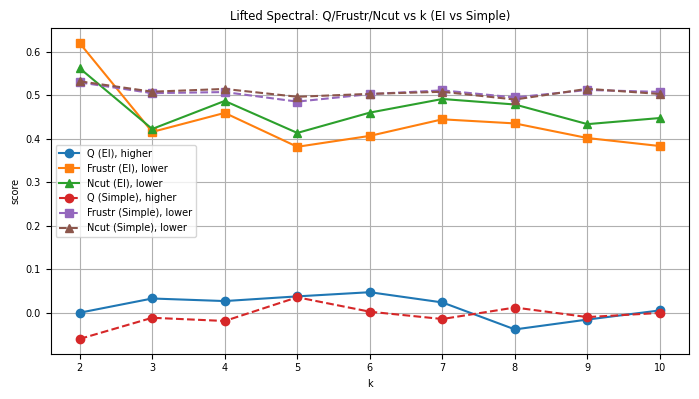

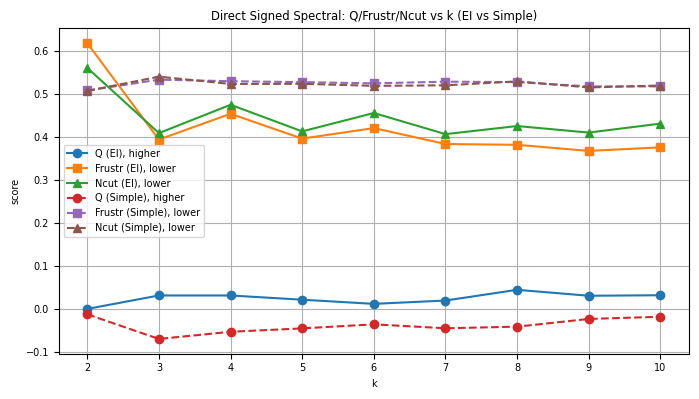

Picked K (lift): {'EI': {'best_Q': 6, 'best_Frustr': 5, 'best_Ncut': 5, 'conservative': 6}, 'Simple': {'best_Q': 5, 'best_Frustr': 5, 'best_Ncut': 8, 'conservative': 5}}
Picked K (direct): {'EI': {'best_Q': 8, 'best_Frustr': 9, 'best_Ncut': 7, 'conservative': 8}, 'Simple': {'best_Q': 2, 'best_Frustr': 2, 'best_Ncut': 2, 'conservative': 2}}


In [10]:
W1 = W_ei.T
W2 = W_simple.T
res, picks = scan_and_plot_two(
    W1, W2,
    k_min=2, k_max=10, restarts=5, seed=0,
    name_ei="EI", name_sm="Simple"
)

print("Picked K (lift):", picks["lift"])
print("Picked K (direct):", picks["direct"])

In [11]:
(df_lift_ei, picks_lift_ei)   = res["lift"]["ei"]
(df_lift_sm, picks_lift_sm)   = res["lift"]["simple"]
(df_dir_ei, picks_dir_ei)     = res["direct"]["ei"]
(df_dir_sm, picks_dir_sm)     = res["direct"]["simple"]

In [12]:
picks_dir_ei["best_Q"], picks_dir_ei["best_Frustr"], picks_dir_ei["best_Ncut"]

(8, 9, 7)

In [13]:
ei_label = df_dir_ei[df_dir_ei["k"] == picks_dir_ei["best_Frustr"]]["labels"].values[0]
print("EI labels for best Frustration:", ei_label)
simple_label = df_dir_sm[df_dir_sm["k"] == picks_dir_sm["best_Frustr"]]["labels"].values[0]
print("Simple labels for best Frustration:", simple_label)

EI labels for best Frustration: [4 3 2 8 4 8 4 1 1 1 7 2 5 7 6 1 8 5 1 7 2 2 8 6 8 3 0 0 2 6 6 5 3 4 4 5 3
 2 8 8 8 5 5 1 6 6 6 0 5 0 8 1 4 8 0 0 1 5 6 2 7 8 7 3]
Simple labels for best Frustration: [1 1 1 0 0 0 1 1 0 0 1 1 0 0 1 0 0 1 1 0 1 1 1 0 0 0 0 1 0 0 0 1 1 1 1 0 0
 0 1 0 0 1 0 0 0 1 1 1 0 1 0 0 0 1 0 0 1 0 0 1 1 0 1 0]


In [14]:
def permutation_from_labels(W, labels, within="out_abs"):
    """
    返回重排索引 perm 以及每个簇的边界位置 boundaries（用于画格线）。
    within: 簇内排序依据
      - 'out_abs': 行 |W| 出强度降序
      - 'in_out_abs': 行(|W|出+|W|入)降序
      - None: 保留原顺序
    """
    labels = np.asarray(labels)
    K = np.unique(labels)
    perm = []
    bounds = []
    start = 0

    # 预先算强度
    absW = np.abs(W)
    out_abs = absW.sum(axis=1)
    in_abs  = absW.sum(axis=0)
    score = {
        'out_abs': out_abs,
        'in_out_abs': out_abs + in_abs
    }.get(within, None)

    for k in K:
        idx = np.where(labels == k)[0]
        if score is not None:
            idx = idx[np.argsort(-score[idx])]
        perm.extend(idx.tolist())
        start += len(idx)
        bounds.append(start)
    perm = np.array(perm, dtype=int)
    return perm, bounds

def plot_reordered_matrix(W, labels, title="Reordered W by clusters", cmap="RdBu_r", vlim="sym", within="out_abs"):
    """
    把 W 的行/列按 labels 同步重排，并画热图；在簇边界画网格线。
    vlim='sym' 表示以对称范围 [-vmax, vmax] 显示（适合有正负权）。
    """
    perm, bounds = permutation_from_labels(W, labels, within=within)
    Wp = W[np.ix_(perm, perm)]

    if vlim == "sym":
        vmax = np.percentile(np.abs(Wp), 99)  # 稍稳健一些
        vmin = -vmax
    else:
        vmin, vmax = None, None

    plt.figure(figsize=(6,6))
    im = plt.imshow(Wp, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    plt.title(title)
    plt.xlabel("post-synaptic (reordered)")
    plt.ylabel("pre-synaptic (reordered)")
    plt.colorbar(im, fraction=0.046, pad=0.04)

    # 画簇边界
    for b in bounds[:-1]:
        plt.axhline(b-0.5, color='k', lw=0.6)
        plt.axvline(b-0.5, color='k', lw=0.6)
    plt.tight_layout()
    plt.show()

    return perm, Wp, bounds  # 如需导出重排后的矩阵

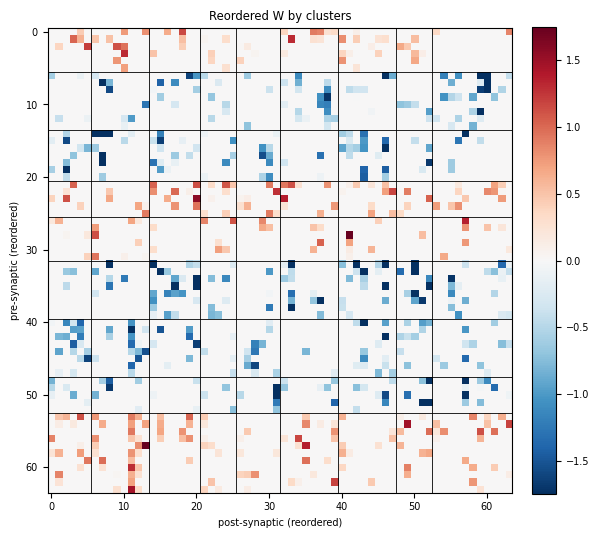

In [15]:
perm, Wp, bounds = plot_reordered_matrix(W_ei.T, ei_label)

Input weight shape: (64, 1)


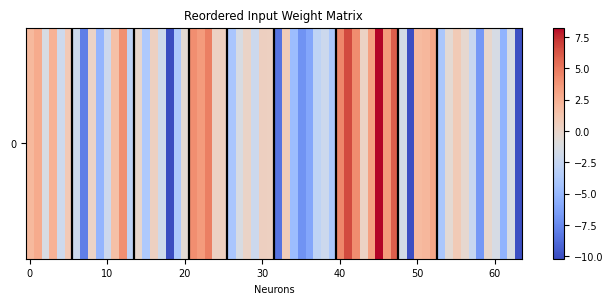

In [16]:
input_weight = net.lstm.input_layer.weight.detach().cpu().numpy()
print("Input weight shape:", input_weight.shape)
reordered_input_weight = input_weight[perm]
reordered_input_weight_transposed = reordered_input_weight.T
plt.figure(figsize=(8,3))
plt.imshow(reordered_input_weight_transposed, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.title('Reordered Input Weight Matrix')
plt.xlabel('Neurons')
# plt.ylabel('Input Features')
for b in bounds[:-1]:
    plt.axvline(b-0.5, color='k', lw=1.6)
plt.yticks(np.arange(input_weight.shape[1]))
plt.show()

Output weight shape: (25, 64)


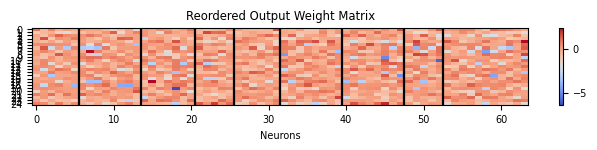

In [17]:
output_weight = net.lstm.output_layer.weight.detach().cpu().numpy()
print("Output weight shape:", output_weight.shape)
reordered_output_weight = output_weight[:, perm]
plt.figure(figsize=(8,1))
plt.imshow(reordered_output_weight, cmap='coolwarm', aspect='auto')
plt.colorbar()
for b in bounds[:-1]:
    plt.axvline(b-0.5, color='k', lw=1.6)
plt.title('Reordered Output Weight Matrix')
plt.xlabel('Neurons')
# plt.ylabel('Output Actions')
plt.yticks(np.arange(output_weight.shape[0]))
plt.show()

In [18]:
import pickle as pkl
variance_info = pkl.load(open('./output/multitask/yang19_variance.pkl', 'rb'))
variance_info_simple = pkl.load(open('./output/multitask/yang19_variance_simple.pkl', 'rb'))
print("Variance info (EI):", variance_info.keys())

FileNotFoundError: [Errno 2] No such file or directory: './output/multitask/yang19_variance.pkl'

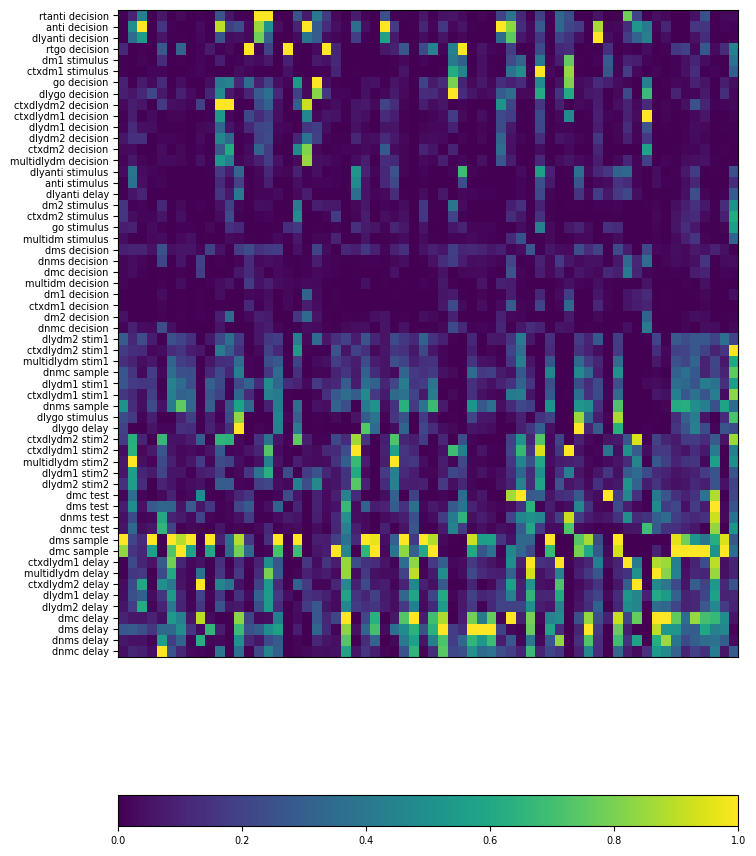

In [ ]:
fig, ax_heat = plt.subplots(figsize=(8, 12))
row_order = variance_info['row_order']
X_ord = variance_info['variance'][row_order][:, perm]
im = ax_heat.imshow(X_ord, aspect='auto', interpolation='nearest', cmap='viridis')
ax_heat.set_xticks([])
ax_heat.set_yticks(np.arange(len(variance_info['titles'])))
ax_heat.set_yticklabels(np.array(variance_info['titles'])[row_order])
cb = fig.colorbar(im, orientation='horizontal')


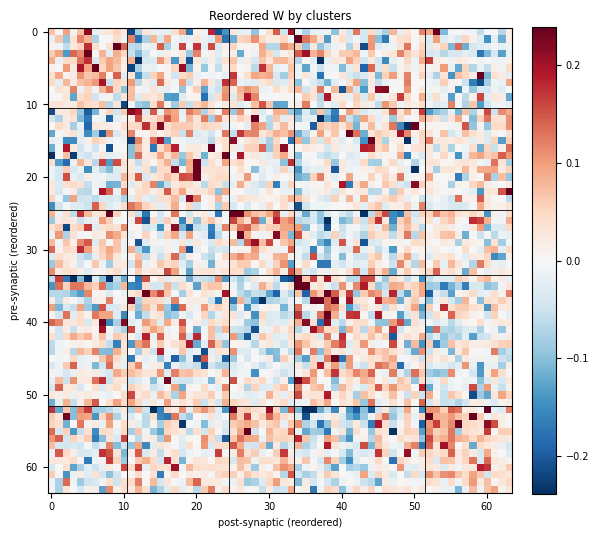

In [ ]:
perm_simple, Wp, bounds = plot_reordered_matrix(W_simple.T, simple_label)

Input weight shape: (64, 25)


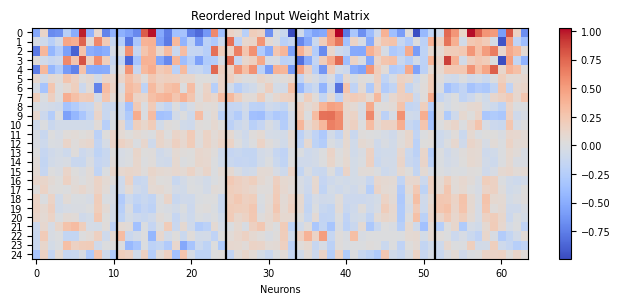

In [ ]:
input_weight = simple_net.lstm.input_layer.weight.detach().cpu().numpy()
print("Input weight shape:", input_weight.shape)
reordered_input_weight = input_weight[perm_simple]
reordered_input_weight_transposed = reordered_input_weight.T
plt.figure(figsize=(8,3))
plt.imshow(reordered_input_weight_transposed, cmap='coolwarm', aspect='auto')
plt.colorbar()
plt.title('Reordered Input Weight Matrix')
plt.xlabel('Neurons')
# plt.ylabel('Input Features')
for b in bounds[:-1]:
    plt.axvline(b-0.5, color='k', lw=1.6)
plt.yticks(np.arange(input_weight.shape[1]))
plt.show()

Output weight shape: (3, 64)


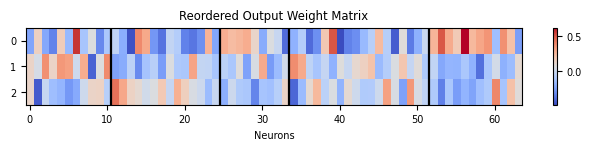

In [ ]:
output_weight = simple_net.lstm.output_layer.weight.detach().cpu().numpy()
print("Output weight shape:", output_weight.shape)
reordered_output_weight = output_weight[:, perm_simple]
plt.figure(figsize=(8,1))
plt.imshow(reordered_output_weight, cmap='coolwarm', aspect='auto')
plt.colorbar()
for b in bounds[:-1]:
    plt.axvline(b-0.5, color='k', lw=1.6)
plt.title('Reordered Output Weight Matrix')
plt.xlabel('Neurons')
# plt.ylabel('Output Actions')
plt.yticks(np.arange(output_weight.shape[0]))
plt.show()

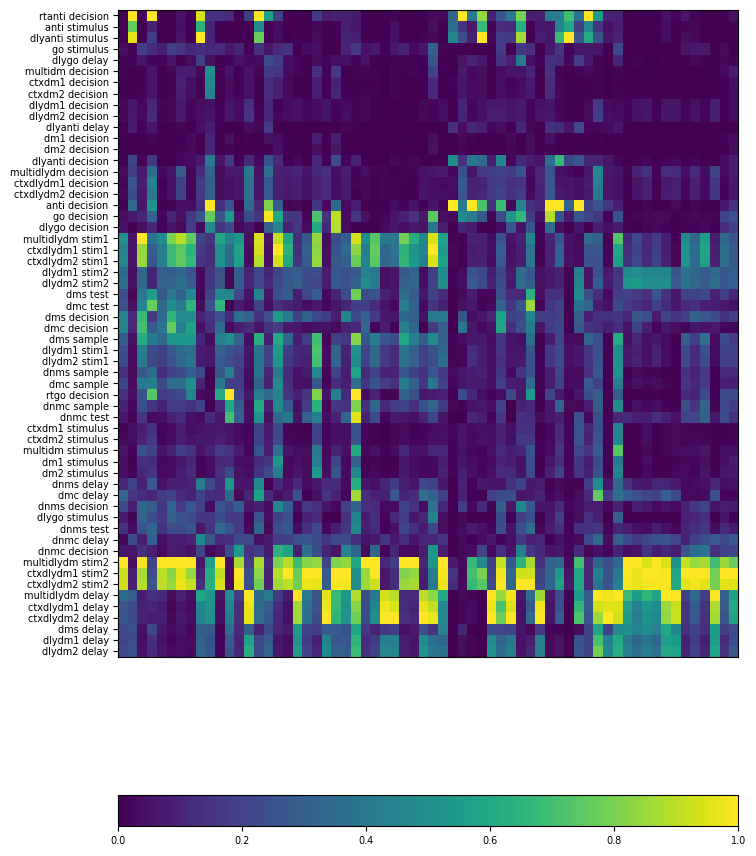

In [ ]:
fig, ax_heat = plt.subplots(figsize=(8, 12))
row_order_simple = variance_info_simple['row_order']
X_ord_simple = variance_info_simple['variance'][row_order_simple][:, perm_simple]
im = ax_heat.imshow(X_ord_simple, aspect='auto', interpolation='nearest', cmap='viridis')
ax_heat.set_xticks([])
ax_heat.set_yticks(np.arange(len(variance_info_simple['titles'])))
ax_heat.set_yticklabels(np.array(variance_info_simple['titles'])[row_order_simple])
cb = fig.colorbar(im, orientation='horizontal')